# 🗽 NYC Airbnb Nightly Rental Price Predictor 
**Objective**: Predict competitive nightly rental prices for New York City Airbnb listings using classical machine learning regression algorithms, with rigorous outlier filtering and hyperparameter tuning.

### Dataset Overview (Kaggle NYC Airbnb Open Data 2019)
- **Target Variable**: `price` (nightly rental cost in USD)
- **Features**:
  - `neighbourhood_group`: NYC Borough (Manhattan, Brooklyn, Queens, Bronx, Staten Island)
  - `neighbourhood`: Specific neighborhood
  - `latitude`, `longitude`: Geospatial coordinates
  - `room_type`: Entire home/apt, Private room, Shared room
  - `minimum_nights`: Minimum stay duration required by host
  - `number_of_reviews`: Total review count
  - `reviews_per_month`: Review accumulation velocity
  - `calculated_host_listings_count`: Amount of listings the host owns
  - `availability_365`: Number of available booking days per year


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score


## 1. Data Inspection


In [2]:
# Load dataset
df = pd.read_csv('data/AB_NYC_2019.csv')

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
display(df.head(3))
df.info()
display(df.describe())


Dataset Shape: 48895 rows, 16 columns



,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365


<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  str    
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     38843 non-n

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


## 2. Outlier Analysis and Filtering

A critical real-world machine learning challenge in real estate data is handling extreme outliers:
- Some listings have **`price = $0`** (erroneous test/placeholder listings).
- Some listings claim **`price = $10,000 / night`** (absurd luxury or fake listings).
Because squared-error loss functions (MSE/RMSE) heavily penalize large errors, extreme outliers severely distort regression coefficients.

We filter the price range to valid realistic market transactions ($10 to $800/night), retaining over **99.5%** of legitimate marketplace listings.


In [3]:
print("=== Price Anomaly Inspection ===")
print(f"Listings with price <= $0: {(df['price'] <= 0).sum()}")
print(f"Listings with price > $800: {(df['price'] > 800).sum()}")
print(f"99th percentile price: ${df['price'].quantile(0.99):.2f}\n")

# Filter extreme outliers
df_clean = df[(df['price'] >= 10) & (df['price'] <= 800)].copy()

# Fill missing reviews_per_month with 0 when reviews == 0
df_clean['reviews_per_month'] = df_clean['reviews_per_month'].fillna(0)

print(f"Retained {len(df_clean)} of {len(df)} records ({len(df_clean)/len(df):.1%})")


=== Price Anomaly Inspection ===
Listings with price <= $0: 11
Listings with price > $800: 420
99th percentile price: $799.00

Retained 48464 of 48895 records (99.1%)


## 3. Exploratory Data Analysis (EDA)


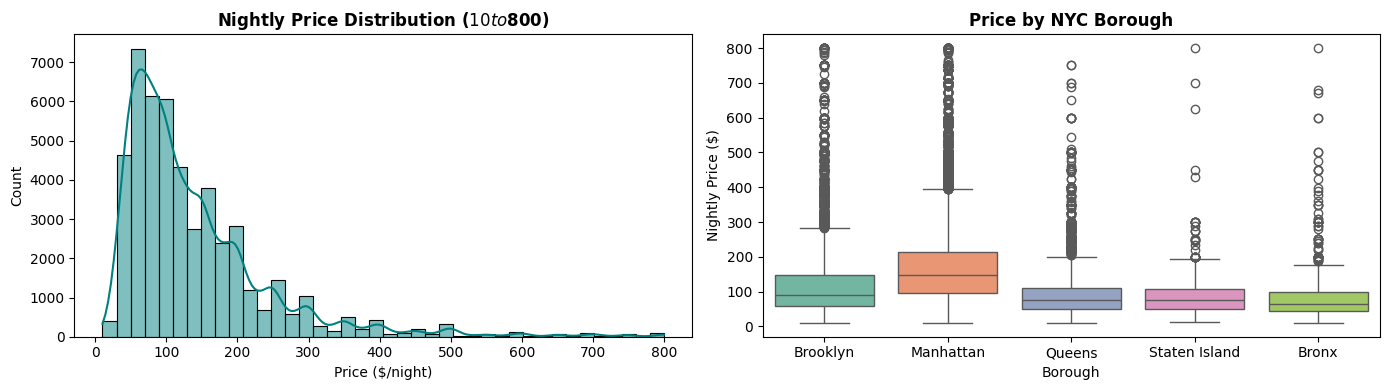

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# 1. Price Distribution after outlier filtering
sns.histplot(df_clean['price'], bins=40, kde=True, color='teal', ax=axes[0])
axes[0].set_title('Nightly Price Distribution ($10 to $800)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Price ($/night)')

# 2. Price by Borough (Neighbourhood Group)
sns.boxplot(data=df_clean, x='neighbourhood_group', y='price', hue='neighbourhood_group', palette='Set2', legend=False, ax=axes[1])
axes[1].set_title('Price by NYC Borough', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Borough')
axes[1].set_ylabel('Nightly Price ($)')

plt.tight_layout()
plt.show()


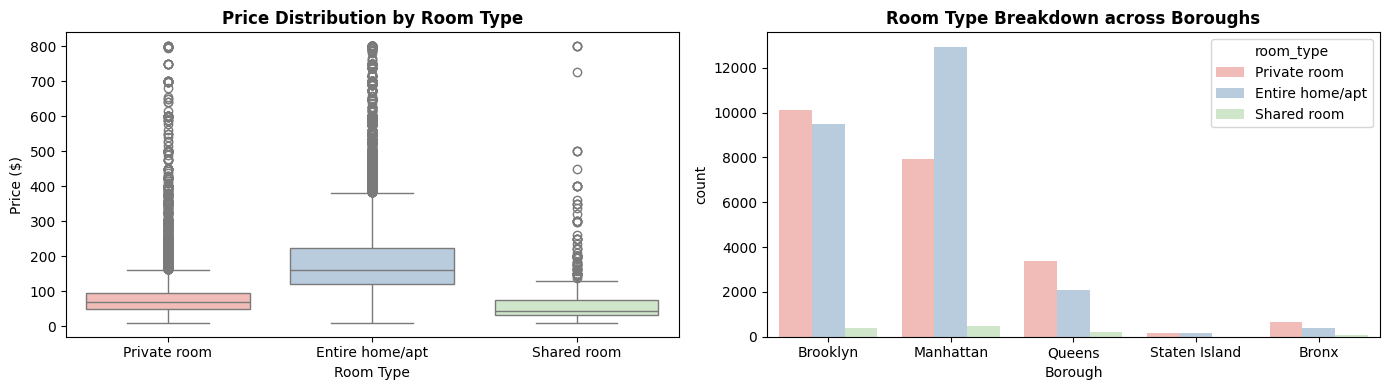

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# 3. Price by Room Type
sns.boxplot(data=df_clean, x='room_type', y='price', hue='room_type', palette='Pastel1', legend=False, ax=axes[0])
axes[0].set_title('Price Distribution by Room Type', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Room Type')
axes[0].set_ylabel('Price ($)')

# 4. NYC Borough Count Breakdown
sns.countplot(data=df_clean, x='neighbourhood_group', hue='room_type', palette='Pastel1', ax=axes[1])
axes[1].set_title('Room Type Breakdown across Boroughs', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Borough')

plt.tight_layout()
plt.show()


## 4. Data Preprocessing 


In [6]:
cat_cols = ['neighbourhood_group', 'room_type']
num_cols = [
    'latitude', 'longitude', 'minimum_nights', 'number_of_reviews',
    'reviews_per_month', 'calculated_host_listings_count', 'availability_365'
]

X = df_clean[cat_cols + num_cols]
y = df_clean['price']

# Train/Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Build Preprocessor
preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols)
])

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set:  {X_test.shape[0]} samples")


Training set: 38771 samples
Testing set:  9693 samples


## 5. Model Training and Hyperparameter Tuning with GridSearchCV

We benchmark and tune three core regression algorithms using **3-Fold Cross-Validation**:
1. **Ridge Regression**: Regularized Linear Regression testing `alpha` penalties.
2. **Random Forest Regressor**: Non-linear ensemble model testing tree depth and estimators.
3. **Gradient Boosting Regressor**: Sequential boosted trees testing learning rates and depth.


In [7]:
# Hyperparameter search configurations
cv = KFold(n_splits=3, shuffle=True, random_state=42)

model_configs = {
    'Ridge Regression': {
        'model': Ridge(),
        'param_grid': {'alpha': [1.0, 10.0, 100.0]}
    },
    'Random Forest': {
        'model': RandomForestRegressor(random_state=42, n_jobs=-1),
        'param_grid': {
            'n_estimators': [50, 100],
            'max_depth': [8, 12]
        }
    },
    'Gradient Boosting': {
        'model': GradientBoostingRegressor(random_state=42),
        'param_grid': {
            'n_estimators': [80, 120],
            'learning_rate': [0.05, 0.1],
            'max_depth': [4, 6]
        }
    }
}

grid_results = {}
best_estimators = {}

for name, config in model_configs.items():
    print(f"\n=================== Tuning {name} ===================")
    grid = GridSearchCV(
        estimator=config['model'],
        param_grid=config['param_grid'],
        cv=cv,
        scoring='neg_root_mean_squared_error',
        n_jobs=-1
    )
    grid.fit(X_train_prep, y_train)
    grid_results[name] = grid
    best_estimators[name] = grid.best_estimator_
    
    print(f"Optimal Parameters: {grid.best_params_}")
    print(f"Best CV RMSE: {-grid.best_score_:.2f}")



=================== Tuning Ridge Regression ===================
Optimal Parameters: {'alpha': 1.0}
Best CV RMSE: 85.67

=================== Tuning Random Forest ===================
Optimal Parameters: {'max_depth': 12, 'n_estimators': 100}
Best CV RMSE: 76.71

=================== Tuning Gradient Boosting ===================
Optimal Parameters: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 120}
Best CV RMSE: 76.46


## 6. Model Evaluation and Comparison 


In [8]:
metrics_list = []

for name, estimator in best_estimators.items():
    y_pred = estimator.predict(X_test_prep)
    
    rmse = root_mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    metrics_list.append({
        'Model': name,
        'Optimal Hyperparameters': str(grid_results[name].best_params_),
        'Test RMSE ($)': f"{rmse:.2f}",
        'Test MAE ($)': f"{mae:.2f}",
        'R² Score': f"{r2:.4f}"
    })

eval_df = pd.DataFrame(metrics_list)
display(eval_df)


,Model,Optimal Hyperparameters,Test RMSE ($),Test MAE ($),R² Score
0,Ridge Regression,{'alpha': 1.0},85.78,53.66,0.3626
1,Random Forest,"{'max_depth': 12, 'n_estimators': 100}",77.12,45.96,0.4849
2,Gradient Boosting,"{'learning_rate': 0.1, 'max_depth': 6, 'n_esti...",76.47,45.76,0.4935


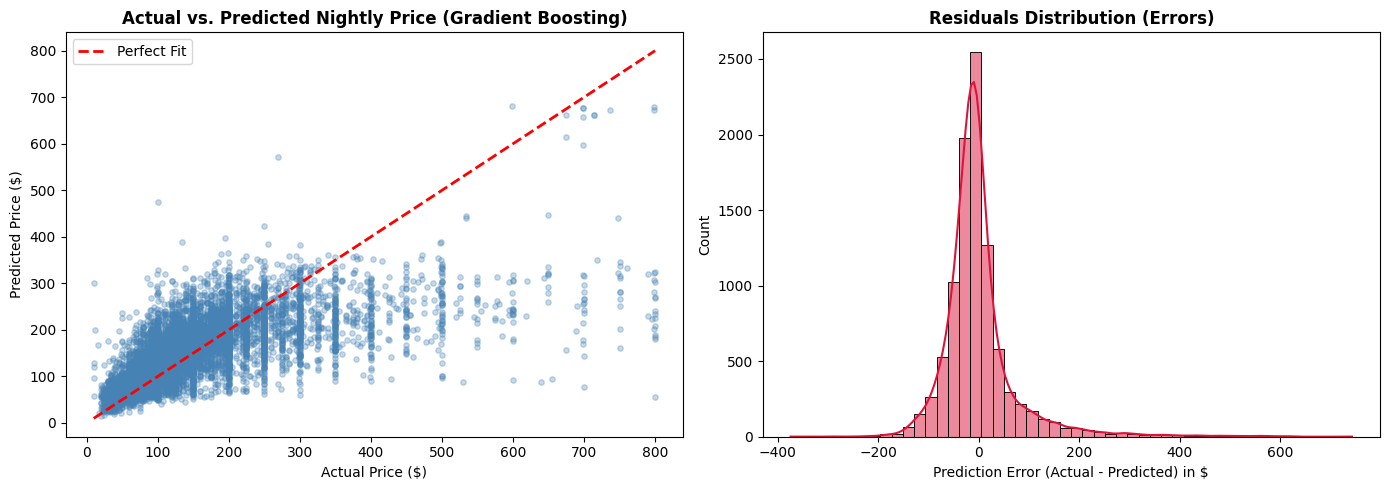

In [9]:
# Actual vs Predicted and Residual Distribution Plots
best_model_name = 'Gradient Boosting'
best_model = best_estimators[best_model_name]
y_pred_best = best_model.predict(X_test_prep)
residuals = y_test - y_pred_best

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs. Predicted
axes[0].scatter(y_test, y_pred_best, alpha=0.3, color='steelblue', s=15)
axes[0].plot([10, 800], [10, 800], 'r--', lw=2, label='Perfect Fit')
axes[0].set_title(f'Actual vs. Predicted Nightly Price ({best_model_name})', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Actual Price ($)')
axes[0].set_ylabel('Predicted Price ($)')
axes[0].legend()

# Residuals distribution
sns.histplot(residuals, bins=50, kde=True, color='crimson', ax=axes[1])
axes[1].set_title('Residuals Distribution (Errors)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Prediction Error (Actual - Predicted) in $')

plt.tight_layout()
plt.show()


## 7. Feature Importance Analysis


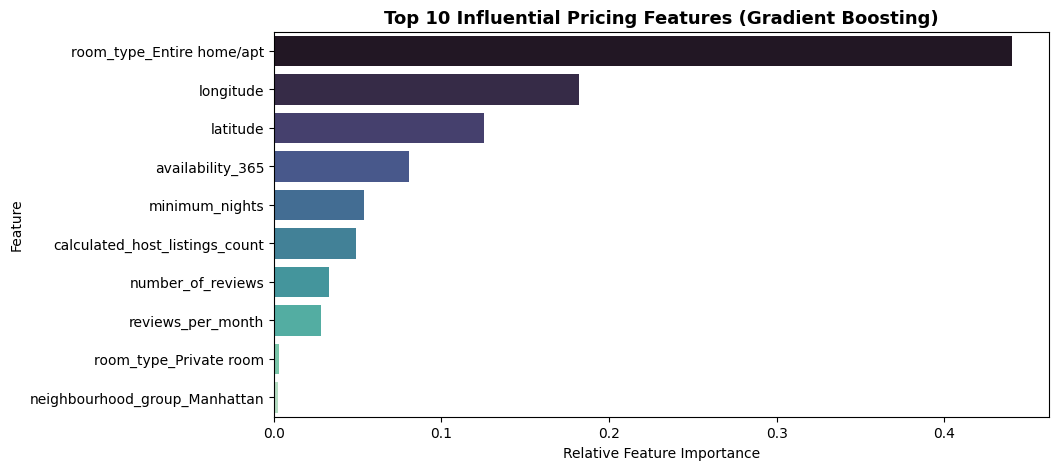

In [10]:
# Extract feature names from preprocessor
encoded_cat_names = preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols)
all_features = list(encoded_cat_names) + num_cols

# Feature importances from Gradient Boosting
importances = best_model.feature_importances_
feat_imp = pd.DataFrame({'Feature': all_features, 'Importance': importances}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=feat_imp.head(10), x='Importance', y='Feature', hue='Feature', palette='mako', legend=False)
plt.title('Top 10 Influential Pricing Features (Gradient Boosting)', fontsize=13, fontweight='bold')
plt.xlabel('Relative Feature Importance')
plt.show()


## 8. Model Serialization for Streamlit Deployment


In [11]:
# Build final end-to-end pipeline
final_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', best_model)
])

# Save pipeline along with sample metadata
borough_averages = df_clean.groupby('neighbourhood_group')['price'].mean().to_dict()
borough_medians = df_clean.groupby('neighbourhood_group')['price'].median().to_dict()

payload = {
    'pipeline': final_pipeline,
    'features': cat_cols + num_cols,
    'borough_averages': borough_averages,
    'borough_medians': borough_medians,
    'cat_cols': cat_cols,
    'num_cols': num_cols
}

joblib.dump(payload, 'airbnb_model.joblib')
print("Model pipeline successfully saved to 'airbnb_model.joblib'")

# Smoke test with a sample Brooklyn listing
sample_listing = pd.DataFrame([{
    'neighbourhood_group': 'Brooklyn',
    'room_type': 'Entire home/apt',
    'latitude': 40.6892,
    'longitude': -73.9855,
    'minimum_nights': 3,
    'number_of_reviews': 25,
    'reviews_per_month': 1.5,
    'calculated_host_listings_count': 1,
    'availability_365': 180
}])

predicted_price = final_pipeline.predict(sample_listing)[0]
print(f"Sample Brooklyn Listing Predicted Price: ${predicted_price:.2f}/night")


Model pipeline successfully saved to 'airbnb_model.joblib'
Sample Brooklyn Listing Predicted Price: $237.83/night
